# From Linear Models to Neural Networks

## Learning Objectives

Module 1 established the basic training loop:

```text
data
→ model
→ prediction
→ loss
→ gradient
→ optimizer
→ parameter update
```

The next question is:

> What happens when the relationship we want to learn cannot be represented by a single linear transformation?

In this notebook we will:

- build a nonlinear dataset
- show the limitation of a linear model
- introduce hidden layers
- understand why activation functions are necessary
- build a small neural network from tensors
- inspect tensor shapes explicitly
- train it using autograd
- compare the manual network with `nn.Module`
- visualize what the network learned

The central idea is:

```text
linear transformation
+
nonlinearity
+
linear transformation
=
basic neural network
```

The training mechanics remain the same as Module 1.

What changes is the model's **capacity to represent functions**.


In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# Reproducibility
torch.manual_seed(42)

print("PyTorch:", torch.__version__)

PyTorch: 2.14.1


## A Problem a Linear Model Cannot Represent Well

A linear regression model has the form:

$$
\hat{y} = wx + b
$$

No matter how we train `w` and `b`, the prediction remains a straight line.

To motivate neural networks, we need a relationship that is genuinely nonlinear.

We will generate data approximately from:

$$
y = x^2 + \epsilon
$$

where $\epsilon$ is random noise.

The underlying relationship is curved:

```text
        •           •
         •         •
          •       •
           •     •
            •   •
             •
              •
```

A straight line cannot represent this shape well.

This gives us a controlled way to answer:

> What does adding a hidden layer and nonlinear activation actually buy us?

In [2]:
# 200 examples with one input feature each
x = torch.linspace(-3, 3, 200).reshape(-1, 1)

# Add moderate random noise
noise = 0.35 * torch.randn(200, 1)

# Nonlinear ground-truth relationship
y = x ** 2 + noise

print("x shape:", x.shape)
print("y shape:", y.shape)

x shape: torch.Size([200, 1])
y shape: torch.Size([200, 1])


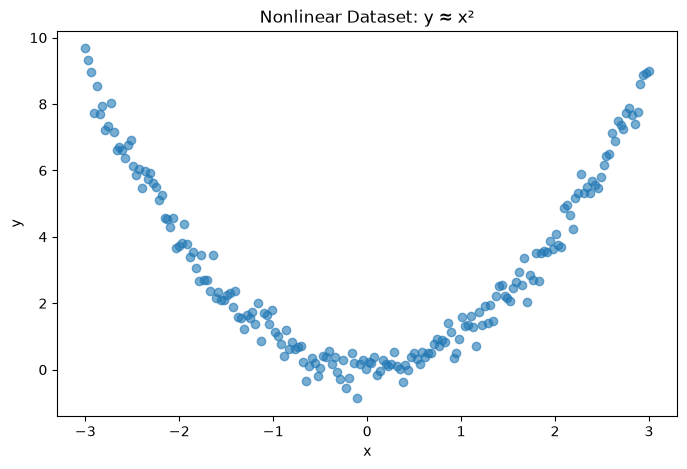

In [3]:
plt.figure(figsize=(8, 5))

plt.scatter(
    x.numpy(),
    y.numpy(),
    alpha=0.6
)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Nonlinear Dataset: y ≈ x²")
plt.show()

## First Hypothesis: Try a Linear Model

Before building a neural network, we should establish a baseline.

The linear model is:

$$
\hat{y} = wx + b
$$

It has only two learnable parameters:

```text
w → slope
b → intercept
```

Because its output is always a straight line, we expect:

```text
optimization may succeed
but
representation may still fail
```

This introduces an important distinction:

```text
optimization problem
vs
model-capacity problem
```

A model can be perfectly optimized and still perform poorly if the function it
needs to learn is outside the set of functions it can represent.

In [4]:
torch.manual_seed(42)

linear_model = nn.Linear(1, 1)

loss_fn = nn.MSELoss()

optimizer = optim.Adam(
    linear_model.parameters(),
    lr=0.05
)

epochs = 500
linear_losses = []

for epoch in range(epochs):
    optimizer.zero_grad()

    # Forward pass
    y_pred = linear_model(x)

    # Compute error
    loss = loss_fn(y_pred, y)
    linear_losses.append(loss.item())

    # Backpropagation
    loss.backward()

    # Parameter update
    optimizer.step()

print("Final linear-model loss:", linear_losses[-1])
print("Weight:", linear_model.weight.item())
print("Bias:", linear_model.bias.item())

Final linear-model loss: 7.336689472198486
Weight: -0.009910548105835915
Bias: 3.046236753463745


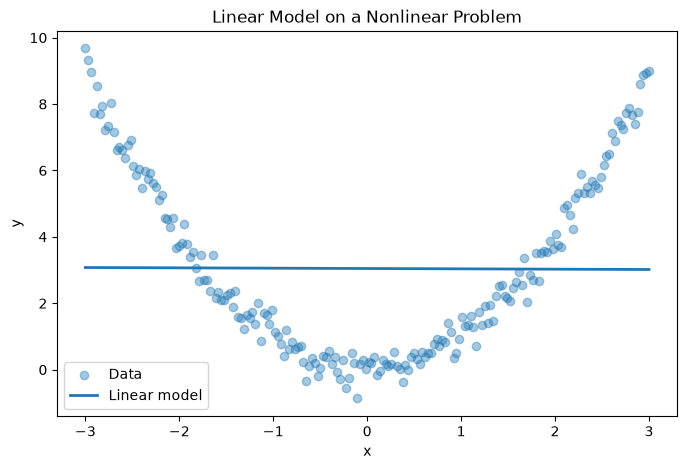

In [5]:
linear_model.eval()

with torch.no_grad():
    linear_predictions = linear_model(x)

plt.figure(figsize=(8, 5))

plt.scatter(
    x.numpy(),
    y.numpy(),
    alpha=0.4,
    label="Data"
)

plt.plot(
    x.numpy(),
    linear_predictions.numpy(),
    linewidth=2,
    label="Linear model"
)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Linear Model on a Nonlinear Problem")
plt.legend()
plt.show()

## Linear Baseline — Interpretation

The trained linear model produced approximately:

```text
loss   = 7.3367
weight = -0.0099
bias   = 3.0462
```

The learned weight is very close to zero, so the prediction is approximately:

$$
\hat{y} \approx 3.05
$$

which appears as an almost horizontal line.

### Why did the slope approach zero?

The target relationship is approximately:

$$
y = x^2
$$

which is symmetric around $x=0$.

For example:

```text
x = -3 → y ≈ 9
x = +3 → y ≈ 9

x = -2 → y ≈ 4
x = +2 → y ≈ 4
```

A positive linear slope could improve the fit on one side of the parabola while
making the opposite side worse.

A negative slope would have the opposite problem.

Because the dataset is roughly symmetric, the best linear compromise has:

```text
w ≈ 0
```

and uses the bias to place a horizontal line near the average vertical level of
the observations.

### Optimization vs representation

This experiment illustrates an important distinction:

```text
optimization
→ find the best parameters available for a model

representation / capacity
→ determine what kinds of functions that model can express
```

The optimizer successfully reduced the loss.

The problem is that no choice of `w` and `b` can transform:

$$
wx+b
$$

into the curved function:

$$
x^2
$$

Therefore:

> **A well-optimized model can still perform poorly when the model class cannot represent the underlying relationship.**

Before changing optimizers or training longer, we should first ask whether the
model has enough representational capacity for the problem.

## Why Stacking Linear Layers Is Not Enough

A natural idea is to add more linear layers.

For example:

$$
h = xW_1+b_1
$$

followed by:

$$
\hat{y} = hW_2+b_2
$$

Substituting the first equation into the second gives:

$$
\hat{y}
=
(xW_1+b_1)W_2+b_2
$$

Expanding:

$$
\hat{y}
=
xW_1W_2+b_1W_2+b_2
$$

Define:

$$
W' = W_1W_2
$$

and:

$$
b' = b_1W_2+b_2
$$

Then:

$$
\hat{y}=xW'+b'
$$

which is still only a linear transformation.

Therefore:

```text
Linear
→ Linear
→ Linear
```

can always collapse into:

```text
one Linear transformation
```

No matter how many purely linear layers we stack, the overall function remains
linear.

To represent genuinely nonlinear relationships, we need to introduce a
**nonlinear activation function** between layers.

The basic neural-network pattern becomes:

```text
input
↓
linear transformation
↓
nonlinear activation
↓
linear transformation
↓
output
```

The nonlinear activation is what prevents the entire network from collapsing
into a single linear transformation.

## Introducing ReLU

A common activation function is the Rectified Linear Unit, or **ReLU**:

$$
\operatorname{ReLU}(z)=\max(0,z)
$$

It behaves as:

```text
negative input → 0
positive input → unchanged
```

Examples:

```text
ReLU(-3) = 0
ReLU(-1) = 0
ReLU(0)  = 0
ReLU(2)  = 2
ReLU(5)  = 5
```

ReLU is simple, but critically it is **nonlinear**.

Once it is inserted between linear transformations:

```text
Linear
↓
ReLU
↓
Linear
```

the entire network can no longer be collapsed into one linear transformation.

This allows the model to represent much richer functions.

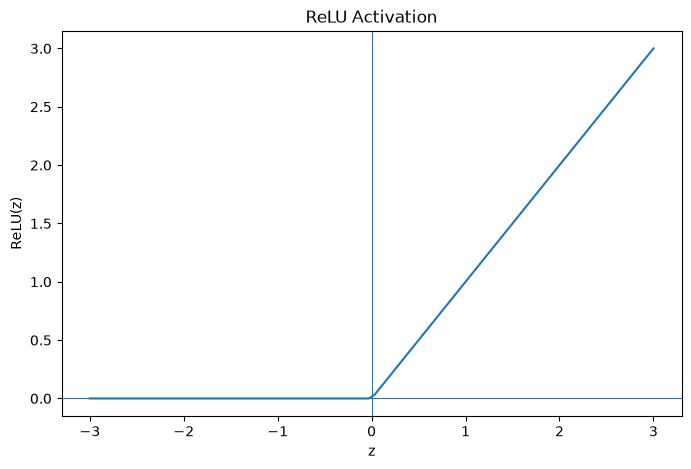

In [8]:
# Example inputs spanning negative and positive values
z = torch.linspace(-3, 3, 100)

# Apply ReLU
relu_z = torch.relu(z)

plt.figure(figsize=(8, 5))

plt.plot(
    z.numpy(),
    relu_z.numpy()
)

plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)

plt.xlabel("z")
plt.ylabel("ReLU(z)")
plt.title("ReLU Activation")
plt.show()

## Building a Two-Layer Neural Network Manually

We now build a small network with one hidden layer.

The structure is:

```text
input
↓
linear transformation
↓
ReLU
↓
linear transformation
↓
prediction
```

For one input feature and `H` hidden units:

```text
x
[N, 1]

↓ W1 + b1

hidden pre-activation
[N, H]

↓ ReLU

hidden activation
[N, H]

↓ W2 + b2

prediction
[N, 1]
```

We will use:

```text
H = 16
```

so each scalar input is transformed into 16 hidden features.

The parameters are:

```text
W1 → [1, 16]
b1 → [16]

W2 → [16, 1]
b2 → [1]
```

The first layer expands:

```text
1 feature
→ 16 learned hidden features
```

The second layer combines those hidden features into:

```text
1 output
```

This is the first point where tensor-shape reasoning becomes essential.

In [9]:
# Number of hidden units
hidden_size = 16

torch.manual_seed(42)

# First linear transformation: 1 input feature -> 16 hidden features
W1 = torch.randn(
    1,
    hidden_size,
    requires_grad=True
)

b1 = torch.zeros(
    hidden_size,
    requires_grad=True
)

# Second linear transformation: 16 hidden features -> 1 output
W2 = torch.randn(
    hidden_size,
    1,
    requires_grad=True
)

b2 = torch.zeros(
    1,
    requires_grad=True
)

print("x shape: ", x.shape)
print("W1 shape:", W1.shape)
print("b1 shape:", b1.shape)
print("W2 shape:", W2.shape)
print("b2 shape:", b2.shape)

x shape:  torch.Size([200, 1])
W1 shape: torch.Size([1, 16])
b1 shape: torch.Size([16])
W2 shape: torch.Size([16, 1])
b2 shape: torch.Size([1])


In [10]:
# First linear transformation
z1 = x @ W1 + b1

# Nonlinear activation
h1 = torch.relu(z1)

# Second linear transformation
y_pred = h1 @ W2 + b2

print("z1 shape:", z1.shape)
print("h1 shape:", h1.shape)
print("y_pred shape:", y_pred.shape)

z1 shape: torch.Size([200, 16])
h1 shape: torch.Size([200, 16])
y_pred shape: torch.Size([200, 1])


## Shape Interpretation

The first transformation is:

```text
x
[200, 1]

@

W1
[1, 16]

=

z1
[200, 16]
```

Each of the 200 examples now has 16 hidden features.

The bias:

```text
b1
[16]
```

is broadcast across all 200 examples.

ReLU does not change the shape:

```text
z1
[200, 16]

→ ReLU →

h1
[200, 16]
```

The second transformation is:

```text
h1
[200, 16]

@

W2
[16, 1]

=

prediction
[200, 1]
```

So the network transforms:

```text
1 input feature
→ 16 hidden features
→ 1 output
```

The hidden representation gives the network more flexibility than a single
linear model.

## Training the Manual Neural Network

The network currently has four learnable parameter tensors:

```text
W1
b1
W2
b2
```

The training loop is still the same:

```text
forward
→ loss
→ backward
→ update
→ clear gradients
→ repeat
```

The only difference from linear regression is that the forward pass now contains
multiple transformations and a nonlinear activation.

We will train the network using Mean Squared Error.

In [11]:
# Learning-rate and training settings
learning_rate = 0.01
epochs = 2000

manual_nn_losses = []

for epoch in range(epochs):
    # -------------------------
    # Forward pass
    # -------------------------
    z1 = x @ W1 + b1
    h1 = torch.relu(z1)
    y_pred = h1 @ W2 + b2

    # -------------------------
    # Loss
    # -------------------------
    loss = ((y_pred - y) ** 2).mean()
    manual_nn_losses.append(loss.item())

    # -------------------------
    # Backward pass
    # -------------------------
    loss.backward()

    # -------------------------
    # Parameter update
    # -------------------------
    with torch.no_grad():
        W1 -= learning_rate * W1.grad
        b1 -= learning_rate * b1.grad
        W2 -= learning_rate * W2.grad
        b2 -= learning_rate * b2.grad

    # -------------------------
    # Clear gradients
    # -------------------------
    W1.grad.zero_()
    b1.grad.zero_()
    W2.grad.zero_()
    b2.grad.zero_()

    if epoch % 200 == 0:
        print(
            f"Epoch {epoch:4d} | "
            f"Loss: {loss.item():.6f}"
        )

Epoch    0 | Loss: 55.635567
Epoch  200 | Loss: 0.410031
Epoch  400 | Loss: 0.343411
Epoch  600 | Loss: 0.286464
Epoch  800 | Loss: 0.244834
Epoch 1000 | Loss: 0.216325
Epoch 1200 | Loss: 0.194506
Epoch 1400 | Loss: 0.175078
Epoch 1600 | Loss: 0.158037
Epoch 1800 | Loss: 0.147204


In [12]:
print("Final manual neural-network loss:", manual_nn_losses[-1])
print("Linear baseline loss:", linear_losses[-1])

Final manual neural-network loss: 0.14007623493671417
Linear baseline loss: 7.336689472198486


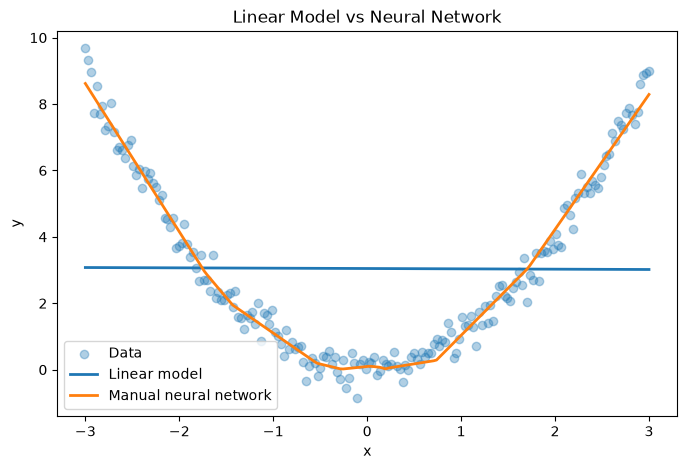

In [13]:
with torch.no_grad():
    z1 = x @ W1 + b1
    h1 = torch.relu(z1)
    manual_nn_predictions = h1 @ W2 + b2

plt.figure(figsize=(8, 5))

plt.scatter(
    x.numpy(),
    y.numpy(),
    alpha=0.35,
    label="Data"
)

plt.plot(
    x.numpy(),
    linear_predictions.numpy(),
    linewidth=2,
    label="Linear model"
)

plt.plot(
    x.numpy(),
    manual_nn_predictions.numpy(),
    linewidth=2,
    label="Manual neural network"
)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Linear Model vs Neural Network")
plt.legend()
plt.show()

## Manual Neural Network — Interpretation

The linear baseline achieved:

```text
loss ≈ 7.3367
```

while the manual neural network achieved:

```text
loss ≈ 0.1401
```

The training loop itself did not fundamentally change.

We still used:

```text
forward
→ loss
→ backward
→ parameter update
→ clear gradients
→ repeat
```

What changed was the model's representational capacity.

The linear model could only express:

$$
\hat{y} = wx+b
$$

which is always a straight line.

The neural network used:

```text
Linear
↓
ReLU
↓
Linear
```

which can represent nonlinear functions.

This demonstrates:

> **A large performance improvement can come from changing the model class, not from changing the optimizer.**

The original linear model was already being optimized successfully. It simply could not represent the curved relationship well.

---

## Why Can ReLU Hidden Units Approximate a Curve?

A single ReLU unit computes something like:

$$
\operatorname{ReLU}(wx+b)
$$

This produces a function with a bend at the point where:

$$
wx+b=0
$$

Each hidden unit can therefore introduce a different bend or breakpoint.

With multiple hidden units:

```text
hidden unit 1 → one breakpoint
hidden unit 2 → another breakpoint
hidden unit 3 → another breakpoint
...
```

The output layer combines these pieces.

Conceptually:

```text
many simple bent functions
        ↓
weighted combination
        ↓
piecewise-linear approximation
```

A parabola is smooth rather than piecewise linear, but enough small linear pieces can approximate it closely.

This is similar to approximating a curve with many short line segments.

---

## Hidden Features

The first layer transformed each scalar input:

```text
x
[200, 1]
```

into:

```text
h1
[200, 16]
```

So each original input value is represented by 16 learned hidden features.

These hidden features are not manually specified.

They emerge from training through the learned values of:

```text
W1
b1
```

The second layer then combines those 16 hidden activations to produce the final prediction.

Conceptually:

```text
raw input
↓
learned intermediate representation
↓
output
```

This idea of learning useful intermediate representations becomes increasingly important as networks become deeper.

## Inspecting Hidden ReLU Features

The hidden layer contains 16 units.

Each hidden unit computes:

$$
z_j = xw_j + b_j
$$

followed by:

$$
h_j = \operatorname{ReLU}(z_j)
$$

So each hidden unit produces its own piecewise-linear feature of the input.

Because each unit has a different learned weight and bias, each one can activate at a different location and with a different slope.

Conceptually:

```text
input x
↓
hidden unit 1 → one learned hinge
hidden unit 2 → another learned hinge
hidden unit 3 → another learned hinge
...
hidden unit 16
↓
output layer combines them
```

The output layer then computes a weighted combination of these hidden features.

The goal of this experiment is to inspect a few hidden activations directly and see what the network learned internally.

In [14]:
# Compute hidden activations using the trained manual network
with torch.no_grad():
    z1 = x @ W1 + b1
    h1 = torch.relu(z1)

print("Hidden activation shape:", h1.shape)

Hidden activation shape: torch.Size([200, 16])


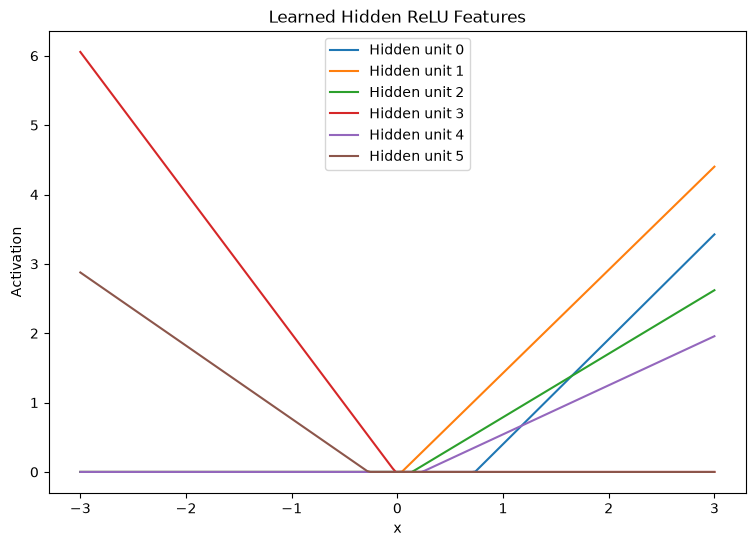

In [15]:
plt.figure(figsize=(9, 6))

# Plot several learned hidden features
for unit in range(6):
    plt.plot(
        x.numpy(),
        h1[:, unit].numpy(),
        label=f"Hidden unit {unit}"
    )

plt.xlabel("x")
plt.ylabel("Activation")
plt.title("Learned Hidden ReLU Features")
plt.legend()
plt.show()

In [16]:
for unit in range(6):
    print(
        f"Unit {unit}: "
        f"weight={W1[0, unit].item(): .4f}, "
        f"bias={b1[unit].item(): .4f}"
    )

Unit 0: weight= 1.5119, bias=-1.1107
Unit 1: weight= 1.4876, bias=-0.0613
Unit 2: weight= 0.9156, bias=-0.1269
Unit 3: weight=-2.0314, bias=-0.0389
Unit 4: weight= 0.7074, bias=-0.1653
Unit 5: weight=-1.0550, bias=-0.2887


## Hidden-Unit Interpretation

Each hidden unit computes:

$$
h_j
=
\operatorname{ReLU}(xw_j+b_j)
$$

The point where that unit switches from inactive to active occurs when:

$$
xw_j+b_j=0
$$

so the breakpoint is approximately:

$$
x=-\frac{b_j}{w_j}
$$

when $w_j \neq 0$.

Therefore, each hidden unit learns two important things:

```text
weight
→ direction and slope

bias
→ where the activation turns on
```

Different hidden units learn different breakpoints.

The network can therefore create multiple linear regions across the input space.

The output layer combines those regions to approximate the nonlinear target.

This gives an important interpretation of the hidden layer:

> The hidden layer is learning a new representation of the input that makes the final prediction easier to construct.

In [17]:
print("Output-layer weights:")

for unit in range(6):
    print(
        f"Hidden unit {unit} contribution weight: "
        f"{W2[unit, 0].item(): .4f}"
    )

print("\nOutput bias:", b2.item())

Output-layer weights:
Hidden unit 0 contribution weight:  1.5825
Hidden unit 1 contribution weight: -0.2146
Hidden unit 2 contribution weight: -0.5423
Hidden unit 3 contribution weight:  0.1378
Hidden unit 4 contribution weight: -0.8001
Hidden unit 5 contribution weight:  0.9145

Output bias: 0.10119161009788513


## Output-Layer Interpretation

Each hidden unit produces a learned feature:

$$
h_j
=
\operatorname{ReLU}(xW_{1,j}+b_{1,j})
$$

The output layer combines those features:

$$
\hat{y}
=
\sum_j W_{2,j}h_j+b_2
$$

The first-layer parameters determine:

```text
where a hidden unit activates
+
how its activation changes with x
```

The output-layer weight determines:

```text
how strongly that hidden feature affects the final prediction
```

A positive output weight pushes the prediction upward when the feature is active.

A negative output weight pushes the prediction downward.

The final nonlinear function is therefore built from many simple learned
piecewise-linear components.

## Visualizing Hidden-Unit Contributions

Each hidden unit produces an activation:

$$
h_j
=
\operatorname{ReLU}(xW_{1,j}+b_{1,j})
$$

The output layer multiplies that activation by a learned weight:

$$
c_j
=
W_{2,j}h_j
$$

where $c_j$ is that unit's contribution to the final prediction.

The full prediction is:

$$
\hat{y}
=
\sum_j c_j+b_2
$$

So the network can be understood as:

```text
hidden feature 1
→ contribution 1

hidden feature 2
→ contribution 2

hidden feature 3
→ contribution 3

...

sum all contributions
+
output bias
↓
final prediction
```

Plotting these contributions lets us see how several simple ReLU pieces combine
into a more complex nonlinear function.

In [18]:
with torch.no_grad():
    # Recompute hidden activations from the trained network
    z1 = x @ W1 + b1
    h1 = torch.relu(z1)

    # Contribution of each hidden unit to the final output
    # h1: [200, 16]
    # W2.T: [1, 16]
    # Broadcasting gives: [200, 16]
    contributions = h1 * W2.T

print("Hidden activations shape:", h1.shape)
print("Contributions shape:", contributions.shape)

Hidden activations shape: torch.Size([200, 16])
Contributions shape: torch.Size([200, 16])


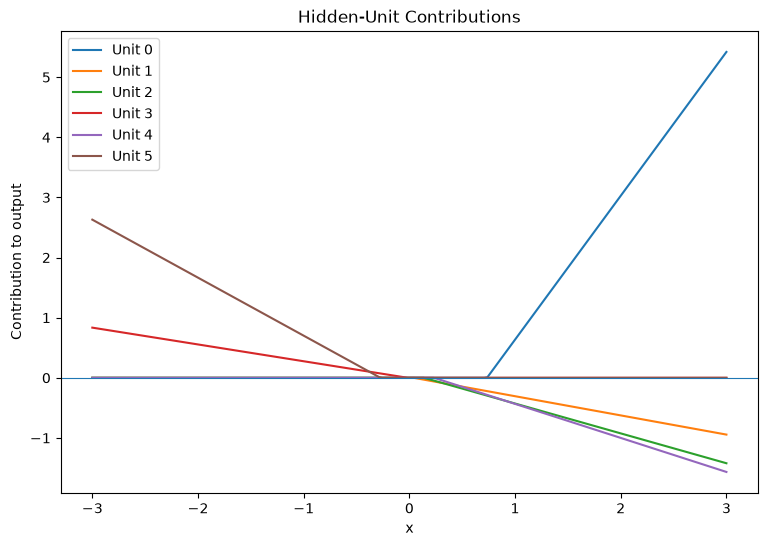

In [19]:
plt.figure(figsize=(9, 6))

for unit in range(6):
    plt.plot(
        x.numpy(),
        contributions[:, unit].numpy(),
        label=f"Unit {unit}"
    )

plt.axhline(0, linewidth=0.8)

plt.xlabel("x")
plt.ylabel("Contribution to output")
plt.title("Hidden-Unit Contributions")
plt.legend()
plt.show()

In [20]:
with torch.no_grad():
    summed_contributions = contributions.sum(
        dim=1,
        keepdim=True
    )

    reconstructed_prediction = (
        summed_contributions + b2
    )

print(
    "Maximum reconstruction difference:",
    torch.max(
        torch.abs(
            reconstructed_prediction
            - manual_nn_predictions
        )
    ).item()
)

Maximum reconstruction difference: 9.5367431640625e-07


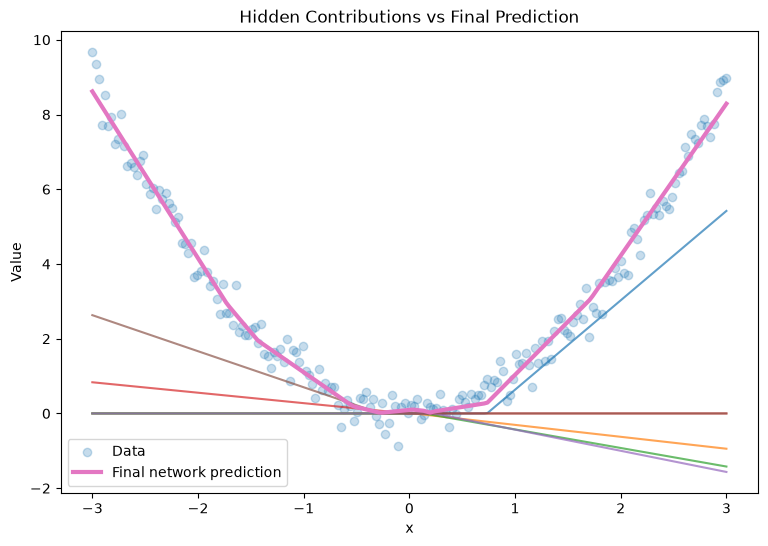

In [21]:
plt.figure(figsize=(9, 6))

plt.scatter(
    x.numpy(),
    y.numpy(),
    alpha=0.25,
    label="Data"
)

for unit in range(6):
    plt.plot(
        x.numpy(),
        contributions[:, unit].numpy(),
        alpha=0.7
    )

plt.plot(
    x.numpy(),
    manual_nn_predictions.numpy(),
    linewidth=3,
    label="Final network prediction"
)

plt.xlabel("x")
plt.ylabel("Value")
plt.title("Hidden Contributions vs Final Prediction")
plt.legend()
plt.show()

## What the Network Actually Learned

The reconstruction error between:

```text
sum of all hidden-unit contributions + output bias
```

and the network's direct prediction was approximately:

```text
9.54e-07
```

which is effectively zero at floating-point precision.

This confirms that the network prediction is literally the weighted sum of the
hidden ReLU features.

The individual hidden-unit contributions are simple piecewise-linear functions.

The final network prediction is much more expressive because those simple
components are added together.

Conceptually:

```text
simple learned hinge
+
simple learned hinge
+
simple learned hinge
+
...
=
nonlinear function approximation
```

This is an important mental model for a shallow ReLU network:

> Complexity emerges from combining many simple learned features.

The hidden units are not individually learning "the parabola."

Instead, they learn useful intermediate pieces, and the output layer combines
those pieces into the final approximation.

## The Same Network Using PyTorch Modules

So far we manually created:

```text
W1, b1
W2, b2
```

and explicitly computed:

```text
x @ W1 + b1
→ ReLU
→ h1 @ W2 + b2
```

PyTorch provides abstractions for these operations:

```text
nn.Linear
nn.ReLU
nn.Sequential
```

A network written as:

```python
nn.Sequential(
    nn.Linear(1, 16),
    nn.ReLU(),
    nn.Linear(16, 1)
)
```

represents the same architecture:

```text
[batch, 1]
↓
Linear(1, 16)
↓
[batch, 16]
↓
ReLU
↓
[batch, 16]
↓
Linear(16, 1)
↓
[batch, 1]
```

The abstraction reduces boilerplate, but the underlying computation is the same.

In [22]:
torch.manual_seed(42)

model = nn.Sequential(
    nn.Linear(1, 16),
    nn.ReLU(),
    nn.Linear(16, 1)
)

print(model)

Sequential(
  (0): Linear(in_features=1, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=1, bias=True)
)


In [23]:
for name, parameter in model.named_parameters():
    print(
        f"{name:20s} "
        f"shape={tuple(parameter.shape)} "
        f"requires_grad={parameter.requires_grad}"
    )

0.weight             shape=(16, 1) requires_grad=True
0.bias               shape=(16,) requires_grad=True
2.weight             shape=(1, 16) requires_grad=True
2.bias               shape=(1,) requires_grad=True


In [24]:
loss_fn = nn.MSELoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.01
)

epochs = 2000
module_losses = []

for epoch in range(epochs):
    optimizer.zero_grad()

    y_pred_module = model(x)

    loss = loss_fn(y_pred_module, y)
    module_losses.append(loss.item())

    loss.backward()
    optimizer.step()

print("Final nn.Sequential loss:", module_losses[-1])
print("Manual network loss:", manual_nn_losses[-1])

Final nn.Sequential loss: 0.11436588317155838
Manual network loss: 0.14007623493671417


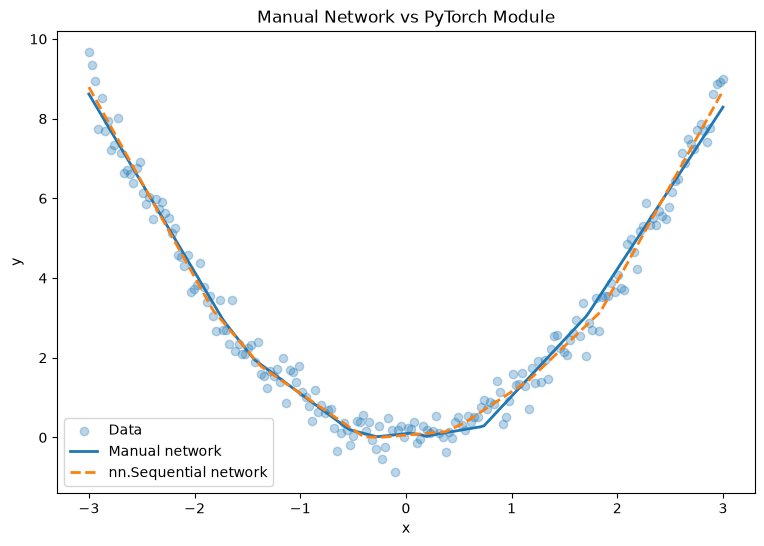

In [25]:
model.eval()

with torch.no_grad():
    module_predictions = model(x)

plt.figure(figsize=(9, 6))

plt.scatter(
    x.numpy(),
    y.numpy(),
    alpha=0.3,
    label="Data"
)

plt.plot(
    x.numpy(),
    manual_nn_predictions.numpy(),
    linewidth=2,
    label="Manual network"
)

plt.plot(
    x.numpy(),
    module_predictions.numpy(),
    linewidth=2,
    linestyle="--",
    label="nn.Sequential network"
)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Manual Network vs PyTorch Module")
plt.legend()
plt.show()

## Manual Network vs `nn.Sequential`

The manual network achieved:

```text
loss ≈ 0.1401
```

while the equivalent PyTorch module achieved:

```text
loss ≈ 0.1144
```

Their learned functions are visually very similar.

This confirms that `nn.Sequential` is not introducing a fundamentally different
kind of model.

It is simply packaging the same operations we previously wrote manually:

```text
matrix multiply
+
bias
+
ReLU
+
matrix multiply
+
bias
```

The abstraction changes the implementation style, not the underlying mathematics.

The exact final losses differ because the parameter initialization and optimization
trajectory are not identical.

The important result is that both implementations learn the nonlinear structure
of the data successfully.

## Experiment: What Happens If We Remove ReLU?

Our neural network architecture currently looks like:

```text
Linear(1, 16)
→ ReLU
→ Linear(16, 1)
```

We argued mathematically that if we remove ReLU:

```text
Linear(1, 16)
→ Linear(16, 1)
```

the two linear transformations should collapse into one equivalent linear
transformation.

That means the model should lose its ability to represent the parabola.

We can test that claim directly.

In [26]:
torch.manual_seed(42)

no_activation_model = nn.Sequential(
    nn.Linear(1, 16),
    nn.Linear(16, 1)
)

optimizer = optim.Adam(
    no_activation_model.parameters(),
    lr=0.01
)

no_activation_losses = []

for epoch in range(2000):
    optimizer.zero_grad()

    predictions = no_activation_model(x)

    loss = loss_fn(predictions, y)
    no_activation_losses.append(loss.item())

    loss.backward()
    optimizer.step()

print(
    "Final loss without activation:",
    no_activation_losses[-1]
)

print(
    "Linear baseline loss:",
    linear_losses[-1]
)

print(
    "ReLU network loss:",
    module_losses[-1]
)

Final loss without activation: 7.336689472198486
Linear baseline loss: 7.336689472198486
ReLU network loss: 0.11436588317155838


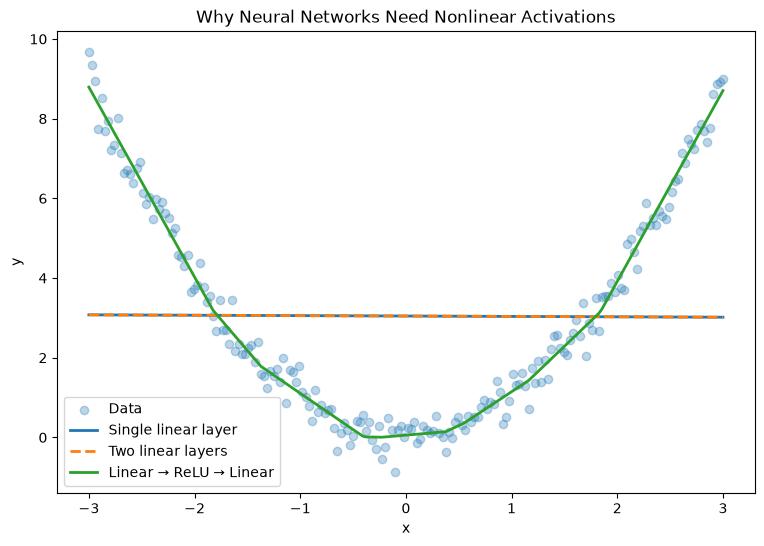

In [27]:
no_activation_model.eval()

with torch.no_grad():
    no_activation_predictions = no_activation_model(x)

plt.figure(figsize=(9, 6))

plt.scatter(
    x.numpy(),
    y.numpy(),
    alpha=0.3,
    label="Data"
)

plt.plot(
    x.numpy(),
    linear_predictions.numpy(),
    linewidth=2,
    label="Single linear layer"
)

plt.plot(
    x.numpy(),
    no_activation_predictions.numpy(),
    linewidth=2,
    linestyle="--",
    label="Two linear layers"
)

plt.plot(
    x.numpy(),
    module_predictions.numpy(),
    linewidth=2,
    label="Linear → ReLU → Linear"
)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Why Neural Networks Need Nonlinear Activations")
plt.legend()
plt.show()

## Removing ReLU — Experimental Result

The results were:

```text
Single linear layer:             loss ≈ 7.3367
Two stacked linear layers:       loss ≈ 7.3367
Linear → ReLU → Linear:          loss ≈ 0.1144
```

The single linear layer and the two-layer model without an activation learned
essentially the same function.

In this run, their final losses were even identical at the displayed precision.

This experimentally confirms the algebraic result:

$$
(xW_1+b_1)W_2+b_2
$$

can always be rewritten as:

$$
xW'+b'
$$

for some equivalent $W'$ and $b'$.

Therefore, adding more linear layers increases the number of parameters in the
implementation, but it does **not** expand the class of functions the model can
represent.

ReLU changes this.

Once we introduce:

```text
Linear
→ ReLU
→ Linear
```

the transformations can no longer collapse into one linear operation.

The model can then construct multiple linear regions and approximate the
nonlinear target.

### Key lesson

> More parameters alone do not necessarily create more useful model capacity.
> The structure of the model matters.

For a feed-forward neural network, nonlinear activations are what allow depth
and hidden units to produce genuinely nonlinear functions.

# What We Learned

This notebook started with a problem that a linear model could not represent:

$$
y \approx x^2
$$

A trained linear model reached a loss of approximately:

```text
7.34
```

The optimizer was working correctly, but the model class was too limited.

We then built a neural network manually:

```text
input
→ Linear
→ ReLU
→ Linear
→ output
```

and reduced the loss to approximately:

```text
0.14
```

The equivalent PyTorch implementation reached approximately:

```text
0.11
```

## 1. Optimization and representation are different problems

A model may be well optimized and still perform poorly because it cannot
represent the required function.

```text
bad result
≠ automatically bad optimizer
```

Sometimes the architecture itself is the limitation.

## 2. Stacking linear transformations is still linear

Without an activation:

```text
Linear
→ Linear
```

collapses mathematically into a single linear transformation.

Our experiment confirmed this: the two-layer linear network produced the same
loss as the original one-layer linear model.

## 3. Nonlinearity gives neural networks expressive power

ReLU:

$$
\operatorname{ReLU}(z)=\max(0,z)
$$

prevents consecutive layers from collapsing into one linear transformation.

This allows the network to represent nonlinear functions.

## 4. Hidden layers learn intermediate representations

The first layer transformed:

```text
[200, 1]
```

into:

```text
[200, 16]
```

Each scalar input became 16 learned hidden features.

These features were not manually designed. Their weights and biases were learned
through gradient descent.

## 5. ReLU units behave like learned hinges

Each hidden unit computes:

$$
\operatorname{ReLU}(xw+b)
$$

and can introduce a breakpoint at approximately:

$$
x=-\frac{b}{w}
$$

Multiple hidden units create multiple linear regions.

Their combination can approximate a smooth nonlinear function.

## 6. Complex behavior can emerge from simple components

The prediction can be written as:

$$
\hat{y}
=
\sum_j
W_{2,j}
\operatorname{ReLU}(xW_{1,j}+b_{1,j})
+b_2
$$

We reconstructed the prediction from the individual hidden-unit contributions
with an error of only approximately:

```text
9.54e-07
```

which is floating-point-level disagreement.

The network's nonlinear behavior therefore comes from combining many simple
learned components.

## 7. PyTorch abstractions preserve the same mathematics

The manual implementation:

```text
x @ W1 + b1
→ ReLU
→ h @ W2 + b2
```

and:

```python
nn.Sequential(
    nn.Linear(1, 16),
    nn.ReLU(),
    nn.Linear(16, 1)
)
```

represent the same basic architecture.

PyTorch removes bookkeeping, but understanding the underlying tensors,
transformations, gradients, and shapes remains essential.

---

The next question is no longer:

> Can a neural network represent a nonlinear function?

We have shown that it can.

The next question is:

> **What determines whether a deeper neural network can actually train well?**

That leads to initialization, gradient flow, vanishing and exploding gradients,
and the mechanics of backpropagation through multiple layers.